# Assignment–02: Comparative Study and Practical Analysis of Generative AI Models

**CO3:** Autoencoder (AE) and Variational Autoencoder (VAE) – image reconstruction
**CO4:** Deep Convolutional GAN (DCGAN) and pretrained Diffusion Model – image generation

**Dataset:** Labeled Faces in the Wild (LFW), 64×64 RGB

### Group members
- Sanskar Ramesh Meharkar — PRN: 202401110029
- Meghana Shirish Innani — PRN: 202401110009
- Dewesh Barapatre  — PRN: 202401110053



## 1. Install and import libraries

In [6]:
!pip -q install -U diffusers transformers accelerate safetensors

In [7]:
import os, glob, tarfile, urllib.request, random, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
import torch
from diffusers import StableDiffusionPipeline

SEED = 2024
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs("figures", exist_ok=True)

results = {}   # every time and metric is stored here, so the summary cell never shows "Not recorded"

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download LFW dataset directly into Colab

In [8]:
DATA_DIR = "/content/lfw_data"
ARCHIVE_PATH = os.path.join(DATA_DIR, "lfw-funneled.tgz")
ARCHIVE_URL = "https://ndownloader.figshare.com/files/5976015"
os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(ARCHIVE_PATH):
    print("Downloading LFW archive. Please wait...")
    urllib.request.urlretrieve(ARCHIVE_URL, ARCHIVE_PATH)
    print("Download finished.")

marker = os.path.join(DATA_DIR, "extracted.txt")
if not os.path.exists(marker):
    print("Extracting archive...")
    with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:
        tar.extractall(path=DATA_DIR)
    open(marker, "w").write("done")

image_paths = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True))
print("Number of JPG images found:", len(image_paths))
if not image_paths:
    raise RuntimeError("No images found. Re-run this cell and check the internet connection.")

Number of JPG images found: 13233


## 3. Preprocess images and create all shared dataset variables
Defines `X`, `train_x`, `test_x`, `train_ds`, `test_ds` and `gan_ds`. Run this cell before training any model.

In [9]:
IMG_SIZE = 64
MAX_IMAGES = 4000
BATCH_SIZE = 64

random.shuffle(image_paths)              # avoid alphabetical (same-person) bias
selected_paths = image_paths[:MAX_IMAGES]

def load_face(path):
    with Image.open(path) as img:
        return np.asarray(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) / 255.0

X = np.stack([load_face(p) for p in selected_paths]).astype("float32")
print("X shape:", X.shape, "| pixel range:", float(X.min()), "to", float(X.max()))

idx = np.random.permutation(len(X))
split = int(0.9 * len(X))                # 90% train / 10% validation
train_x, test_x = X[idx[:split]], X[idx[split:]]

train_ds = tf.data.Dataset.from_tensor_slices((train_x, train_x)).shuffle(1000, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds  = tf.data.Dataset.from_tensor_slices((test_x, test_x)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
gan_ds   = tf.data.Dataset.from_tensor_slices(train_x).shuffle(1000, seed=SEED).batch(BATCH_SIZE, drop_remainder=True).prefetch(tf.data.AUTOTUNE)

print("Training images:", len(train_x), "| Validation images:", len(test_x))

X shape: (4000, 64, 64, 3) | pixel range: 0.0 to 1.0
Training images: 3600 | Validation images: 400


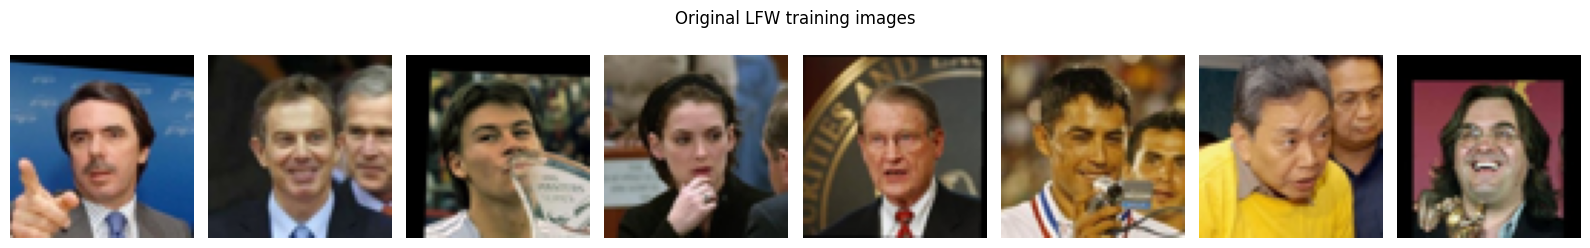

In [10]:
def show_images(images, title, count=8, path=None):
    count = min(count, len(images))
    fig, axes = plt.subplots(1, count, figsize=(2*count, 2.5))
    for ax, im in zip(axes, images[:count]):
        ax.imshow(np.clip(im, 0, 1)); ax.axis("off")
    plt.suptitle(title); plt.tight_layout()
    if path: plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

show_images(train_x, "Original LFW training images", path="figures/fig1_dataset.png")

## 4. Autoencoder (AE) – image reconstruction
The encoder compresses each 64×64 image into a latent vector; the decoder reconstructs the image from it. Loss: MSE.

In [11]:
LATENT_DIM = 256

def build_autoencoder():
    inp = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = tf.keras.layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(inp)   # 32x32
    x = tf.keras.layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)     # 16x16
    x = tf.keras.layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)    # 8x8
    x = tf.keras.layers.Flatten()(x)
    z = tf.keras.layers.Dense(LATENT_DIM, name="latent_vector")(x)
    encoder = tf.keras.Model(inp, z, name="AE_Encoder")

    z_in = tf.keras.Input(shape=(LATENT_DIM,))
    y = tf.keras.layers.Dense(8*8*128, activation="relu")(z_in)
    y = tf.keras.layers.Reshape((8, 8, 128))(y)
    y = tf.keras.layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(y)
    y = tf.keras.layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(y)
    y = tf.keras.layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(y)
    out = tf.keras.layers.Conv2D(3, 3, padding="same", activation="sigmoid")(y)
    decoder = tf.keras.Model(z_in, out, name="AE_Decoder")
    return encoder, decoder, tf.keras.Model(inp, decoder(encoder(inp)), name="Autoencoder")

ae_encoder, ae_decoder, ae = build_autoencoder()
ae.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
ae.summary()

Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AE_Encoder (Functional)         │ (None, 256)            │     2,190,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AE_Decoder (Functional)         │ (None, 64, 64, 3)      │     2,346,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,536,707 (17.31 MB)

 Trainable params: 4,536,707 (17.31 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 18s 148ms/step - loss: 0.0705 - val_loss: 0.0482
Epoch 2/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0356 - val_loss: 0.0298
Epoch 3/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0253 - val_loss: 0.0245
Epoch 4/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0208 - val_loss: 0.0200
Epoch 5/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0176 - val_loss: 0.0176
Epoch 6/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0150 - val_loss: 0.0159
Epoch 7/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0132 - val_loss: 0.0142
Epoch 8/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0118 - val_loss: 0.0129
Epoch 9/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0108 - val_loss: 0.0122
Epoch 10/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0104 - val_loss: 0.0120
Epoch 11/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0095 - val_loss: 0.0115
Epoch 12/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0

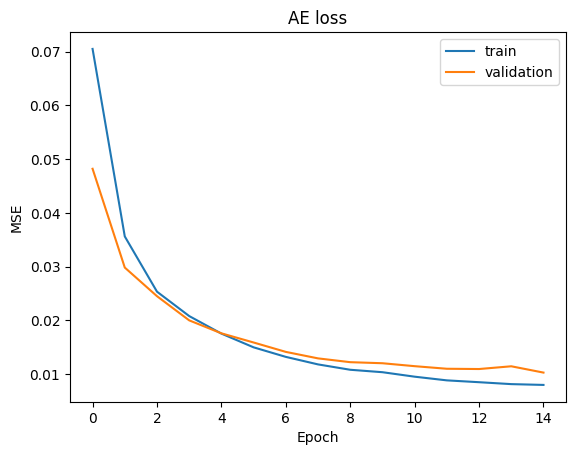

In [12]:
EPOCHS_AE = 15
t0 = time.time()
ae_history = ae.fit(train_ds, validation_data=test_ds, epochs=EPOCHS_AE)
results["ae_time"] = time.time() - t0
print(f"AE training time: {results['ae_time']:.1f} seconds")

plt.plot(ae_history.history["loss"], label="train"); plt.plot(ae_history.history["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("AE loss"); plt.legend()
plt.savefig("figures/fig_ae_loss.png", dpi=150, bbox_inches="tight"); plt.show()

AE: MSE 0.01030 | PSNR 20.24 dB | SSIM 0.5988


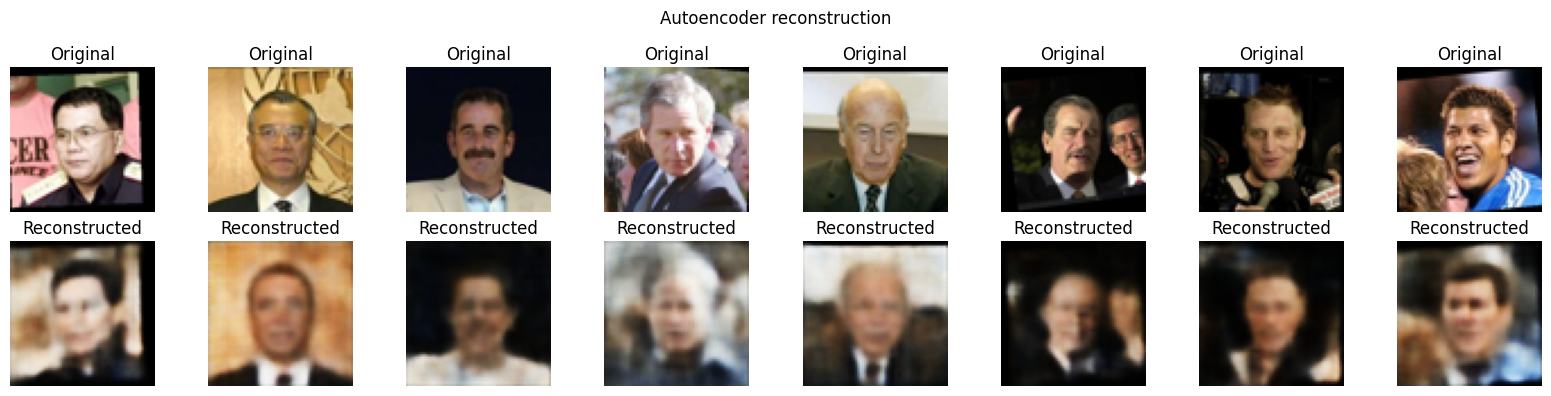

In [13]:
def compare_original_reconstructed(original, reconstructed, title, path=None):
    n = min(len(original), len(reconstructed), 8)
    fig, axes = plt.subplots(2, n, figsize=(2*n, 4))
    for i in range(n):
        axes[0, i].imshow(np.clip(original[i], 0, 1)); axes[0, i].set_title("Original"); axes[0, i].axis("off")
        axes[1, i].imshow(np.clip(reconstructed[i], 0, 1)); axes[1, i].set_title("Reconstructed"); axes[1, i].axis("off")
    plt.suptitle(title); plt.tight_layout()
    if path: plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

def reconstruction_metrics(name, recon):
    results[name+"_mse"]  = float(np.mean((test_x - recon) ** 2))
    results[name+"_psnr"] = float(tf.reduce_mean(tf.image.psnr(test_x, recon, 1.0)))
    results[name+"_ssim"] = float(tf.reduce_mean(tf.image.ssim(test_x, recon, 1.0)))
    print(f"{name.upper()}: MSE {results[name+'_mse']:.5f} | PSNR {results[name+'_psnr']:.2f} dB | SSIM {results[name+'_ssim']:.4f}")

ae_recon_all = ae.predict(test_x, verbose=0)
reconstruction_metrics("ae", ae_recon_all)
compare_original_reconstructed(test_x[:8], ae_recon_all[:8], "Autoencoder reconstruction", "figures/fig_ae_recon.png")

## 5. Variational Autoencoder (VAE) – image reconstruction
The VAE encoder outputs a mean and log-variance; a latent vector is sampled with the reparameterisation trick. Loss = reconstruction (BCE) + KL divergence.

In [14]:
VAE_LATENT_DIM = 256

vae_input = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
h = tf.keras.layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(vae_input)
h = tf.keras.layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(h)
h = tf.keras.layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(h)
h = tf.keras.layers.Flatten()(h)
h = tf.keras.layers.Dense(512, activation="relu")(h)
z_mean = tf.keras.layers.Dense(VAE_LATENT_DIM, name="z_mean")(h)
z_log_var = tf.keras.layers.Dense(VAE_LATENT_DIM, name="z_log_var")(h)

class Sampling(tf.keras.layers.Layer):
    def call(self, inputs):
        mean, log_var = inputs
        return mean + tf.exp(0.5 * log_var) * tf.random.normal(tf.shape(mean))

vae_encoder = tf.keras.Model(vae_input, [z_mean, z_log_var, Sampling()([z_mean, z_log_var])], name="VAE_Encoder")

lat_in = tf.keras.Input(shape=(VAE_LATENT_DIM,))
d = tf.keras.layers.Dense(8*8*128, activation="relu")(lat_in)
d = tf.keras.layers.Reshape((8, 8, 128))(d)
d = tf.keras.layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(d)
d = tf.keras.layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(d)
d = tf.keras.layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(d)
vae_decoder = tf.keras.Model(lat_in, tf.keras.layers.Conv2D(3, 3, padding="same", activation="sigmoid")(d), name="VAE_Decoder")

class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder = encoder, decoder
        self.total_tracker = tf.keras.metrics.Mean(name="loss")
        self.rec_tracker = tf.keras.metrics.Mean(name="reconstruction_loss")
        self.kl_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_tracker, self.rec_tracker, self.kl_tracker]

    def _compute_losses(self, images, training):
        mean, log_var, z = self.encoder(images, training=training)
        recon = self.decoder(z, training=training)
        bce = tf.keras.backend.binary_crossentropy(images, recon)
        rec = tf.reduce_mean(tf.reduce_sum(bce, axis=[1, 2, 3]))
        kl = -0.5 * tf.reduce_mean(tf.reduce_sum(1 + log_var - tf.square(mean) - tf.exp(log_var), axis=1))
        return rec, kl

    def _report_metrics(self, rec, kl):
        self.total_tracker.update_state(rec + kl); self.rec_tracker.update_state(rec); self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def train_step(self, data):
        images = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            rec, kl = self._compute_losses(images, True)
            total = rec + kl
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return self._report_metrics(rec, kl)

    def test_step(self, data):
        images = data[0] if isinstance(data, (tuple, list)) else data
        rec, kl = self._compute_losses(images, False)
        return self._report_metrics(rec, kl)

    def call(self, images, training=False):
        _, _, z = self.encoder(images, training=training)
        return self.decoder(z, training=training)

vae = VAE(vae_encoder, vae_decoder, name="VariationalAutoencoder")
vae.compile(optimizer=tf.keras.optimizers.Adam(1e-3))

Epoch 1/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 14s 126ms/step - kl_loss: 21.4438 - loss: 7907.4287 - reconstruction_loss: 7885.9839 - val_kl_loss: 25.9983 - val_loss: 7610.8921 - val_reconstruction_loss: 7584.8936
Epoch 2/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - kl_loss: 38.0942 - loss: 7438.8335 - reconstruction_loss: 7400.7383 - val_kl_loss: 53.2352 - val_loss: 7330.6709 - val_reconstruction_loss: 7277.4360
Epoch 3/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - kl_loss: 57.6789 - loss: 7190.5566 - reconstruction_loss: 7132.8794 - val_kl_loss: 76.5148 - val_loss: 7055.8003 - val_reconstruction_loss: 6979.2847
Epoch 4/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - kl_loss: 75.2795 - loss: 6991.5581 - reconstruction_loss: 6916.2769 - val_kl_loss: 76.9728 - val_loss: 6988.8828 - val_reconstruction_loss: 6911.9097
Epoch 5/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - kl_loss: 82.5334 - loss: 6918.8750 - reconstruction_loss: 6836.3433 - val_kl_loss: 80.6854 - val_loss: 6919.6475 - val_reconstruction

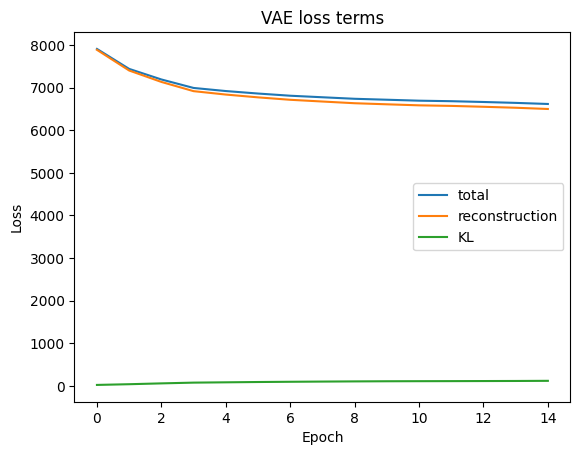

VAE: MSE 0.02337 | PSNR 16.60 dB | SSIM 0.4194


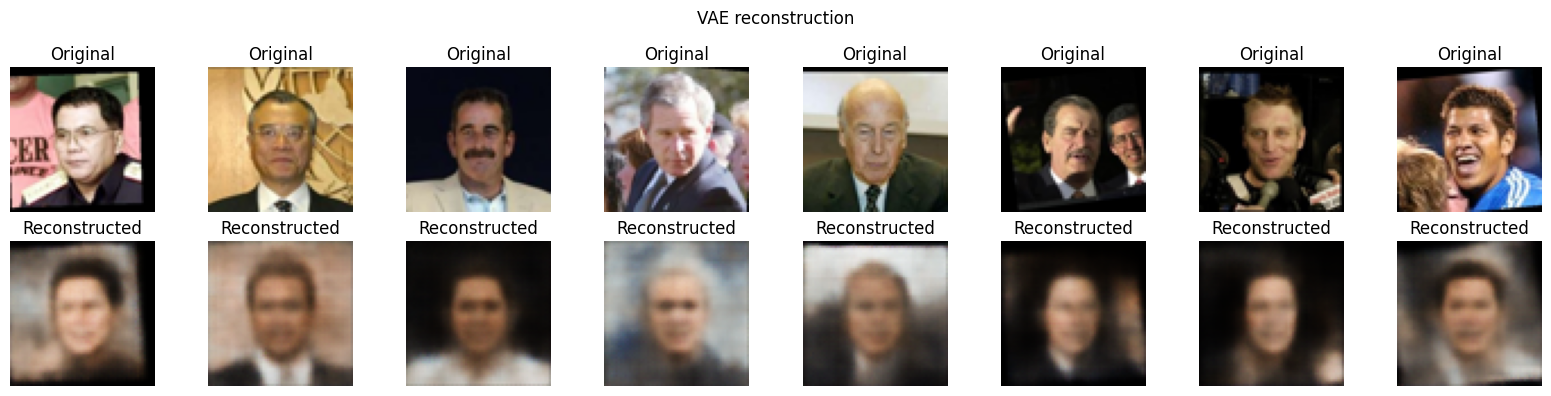

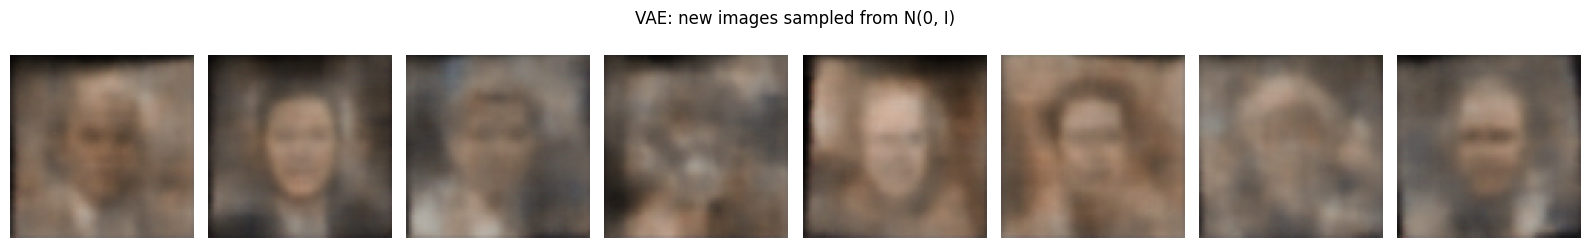

In [15]:
EPOCHS_VAE = 15
t0 = time.time()
vae_history = vae.fit(train_ds, validation_data=test_ds, epochs=EPOCHS_VAE)
results["vae_time"] = time.time() - t0
print(f"VAE training time: {results['vae_time']:.1f} seconds")

for k, lab in [("loss", "total"), ("reconstruction_loss", "reconstruction"), ("kl_loss", "KL")]:
    plt.plot(vae_history.history[k], label=lab)
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("VAE loss terms"); plt.legend()
plt.savefig("figures/fig_vae_loss.png", dpi=150, bbox_inches="tight"); plt.show()

vae_recon_all = vae.predict(test_x, verbose=0)
reconstruction_metrics("vae", vae_recon_all)
compare_original_reconstructed(test_x[:8], vae_recon_all[:8], "VAE reconstruction", "figures/fig_vae_recon.png")

# New faces sampled from the latent space (used in Activity B)
vae_samples = vae_decoder(tf.random.normal((8, VAE_LATENT_DIM))).numpy()
show_images(vae_samples, "VAE: new images sampled from N(0, I)", path="figures/fig_vae_samples.png")

## 6. DCGAN – image generation
The generator turns random noise into a face-like image; the discriminator tries to tell real from generated images.
Stabilisers used: BatchNorm, Dropout, discriminator input noise, one-sided label smoothing (0.9), fixed noise for checkpoint images.

GAN losses fluctuate and do not measure image quality: judge the result from the generated images. If the discriminator loss stays near 1.386 (= 2·ln 2) for many epochs, the discriminator is guessing at chance level.

In [16]:
NOISE_DIM = 100

generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(NOISE_DIM,)),
    tf.keras.layers.Dense(8*8*256, use_bias=False),
    tf.keras.layers.BatchNormalization(), tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Reshape((8, 8, 256)),
    tf.keras.layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(), tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(), tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Conv2DTranspose(3, 4, strides=2, padding="same", activation="tanh"),
], name="DCGAN_Generator")

discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.GaussianNoise(0.05),
    tf.keras.layers.Conv2D(64, 4, strides=2, padding="same"), tf.keras.layers.LeakyReLU(0.2), tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Conv2D(128, 4, strides=2, padding="same"), tf.keras.layers.LeakyReLU(0.2), tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Conv2D(256, 4, strides=2, padding="same"), tf.keras.layers.LeakyReLU(0.2), tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Flatten(), tf.keras.layers.Dense(1),
], name="DCGAN_Discriminator")

bce_logits = tf.keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = tf.keras.optimizers.Adam(1e-4, beta_1=0.5)
fixed_noise = tf.random.normal([16, NOISE_DIM], seed=SEED)

@tf.function
def dcgan_train_step(real_images):
    n = tf.shape(real_images)[0]
    noise = tf.random.normal([n, NOISE_DIM])
    real_images = real_images * 2.0 - 1.0          # [0,1] -> [-1,1] to match tanh
    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
        fake = generator(noise, training=True)
        real_out = discriminator(real_images, training=True)
        fake_out = discriminator(fake, training=True)
        g_loss = bce_logits(tf.ones_like(fake_out), fake_out)
        d_loss = bce_logits(tf.ones_like(real_out) * 0.9, real_out) + bce_logits(tf.zeros_like(fake_out), fake_out)
    g_opt.apply_gradients(zip(g_tape.gradient(g_loss, generator.trainable_variables), generator.trainable_variables))
    d_opt.apply_gradients(zip(d_tape.gradient(d_loss, discriminator.trainable_variables), discriminator.trainable_variables))
    return g_loss, d_loss

def display_dcgan_samples(title, path=None):
    imgs = (generator(fixed_noise, training=False).numpy() + 1.0) / 2.0
    fig, axes = plt.subplots(4, 4, figsize=(6, 6))
    for ax, im in zip(axes.flat, imgs):
        ax.imshow(np.clip(im, 0, 1)); ax.axis("off")
    plt.suptitle(title); plt.tight_layout()
    if path: plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return imgs

Epoch 01/40 | G loss: 1.3723 | D loss: 0.8655


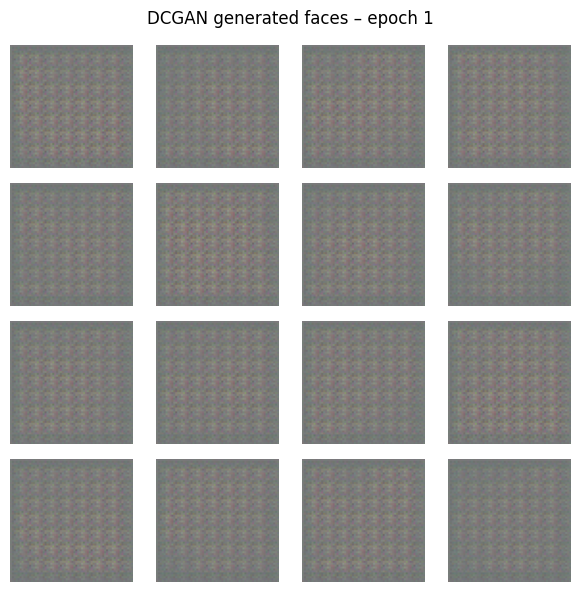

Epoch 02/40 | G loss: 1.5209 | D loss: 0.9147
Epoch 03/40 | G loss: 1.0445 | D loss: 1.2075
Epoch 04/40 | G loss: 0.8891 | D loss: 1.3684
Epoch 05/40 | G loss: 0.8873 | D loss: 1.3449
Epoch 06/40 | G loss: 0.8341 | D loss: 1.4025
Epoch 07/40 | G loss: 0.8454 | D loss: 1.3676
Epoch 08/40 | G loss: 0.8313 | D loss: 1.3807
Epoch 09/40 | G loss: 0.8288 | D loss: 1.3731
Epoch 10/40 | G loss: 0.8216 | D loss: 1.3806


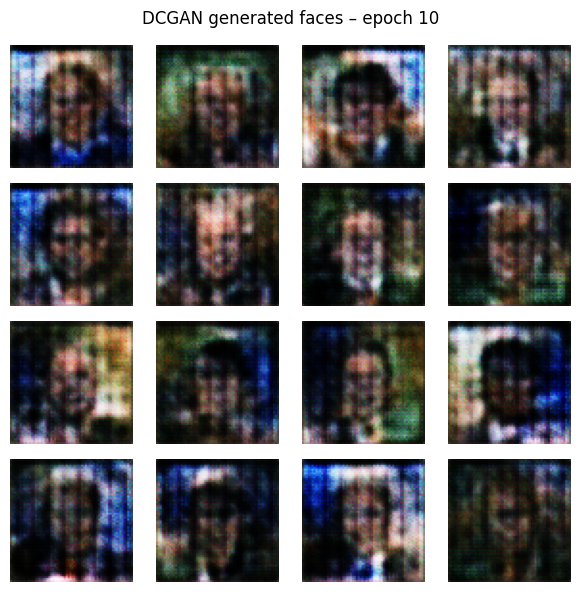

Epoch 11/40 | G loss: 0.8082 | D loss: 1.3827
Epoch 12/40 | G loss: 0.8189 | D loss: 1.3669
Epoch 13/40 | G loss: 0.8114 | D loss: 1.3800
Epoch 14/40 | G loss: 0.8154 | D loss: 1.3587
Epoch 15/40 | G loss: 0.8244 | D loss: 1.3580
Epoch 16/40 | G loss: 0.8174 | D loss: 1.3695
Epoch 17/40 | G loss: 0.8169 | D loss: 1.3620
Epoch 18/40 | G loss: 0.8330 | D loss: 1.3627
Epoch 19/40 | G loss: 0.8254 | D loss: 1.3556
Epoch 20/40 | G loss: 0.8267 | D loss: 1.3643


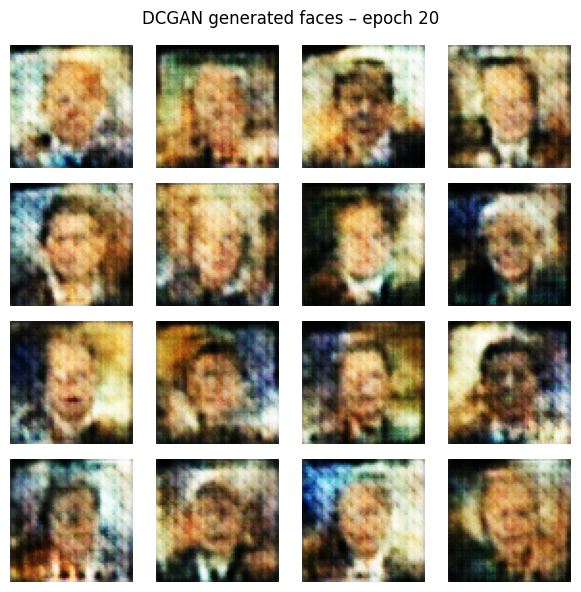

Epoch 21/40 | G loss: 0.8089 | D loss: 1.3600
Epoch 22/40 | G loss: 0.8358 | D loss: 1.3499
Epoch 23/40 | G loss: 0.8367 | D loss: 1.3471
Epoch 24/40 | G loss: 0.8668 | D loss: 1.3451
Epoch 25/40 | G loss: 0.8385 | D loss: 1.3350
Epoch 26/40 | G loss: 0.8737 | D loss: 1.3353
Epoch 27/40 | G loss: 0.8604 | D loss: 1.3364
Epoch 28/40 | G loss: 0.8484 | D loss: 1.3310
Epoch 29/40 | G loss: 0.8590 | D loss: 1.3155
Epoch 30/40 | G loss: 0.8445 | D loss: 1.3440


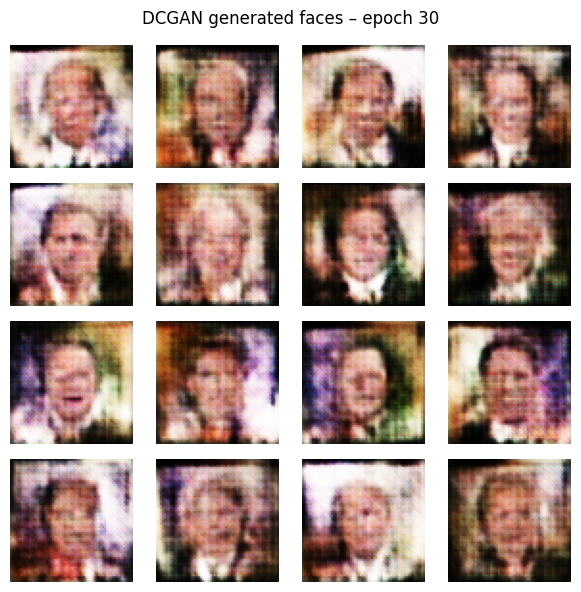

Epoch 31/40 | G loss: 0.8899 | D loss: 1.3193
Epoch 32/40 | G loss: 0.9291 | D loss: 1.2962
Epoch 33/40 | G loss: 0.8555 | D loss: 1.3110
Epoch 34/40 | G loss: 0.9019 | D loss: 1.3054
Epoch 35/40 | G loss: 0.9690 | D loss: 1.2548
Epoch 36/40 | G loss: 0.8791 | D loss: 1.3170
Epoch 37/40 | G loss: 0.8731 | D loss: 1.3031
Epoch 38/40 | G loss: 0.9426 | D loss: 1.2670
Epoch 39/40 | G loss: 0.9930 | D loss: 1.2574
Epoch 40/40 | G loss: 0.8875 | D loss: 1.2795


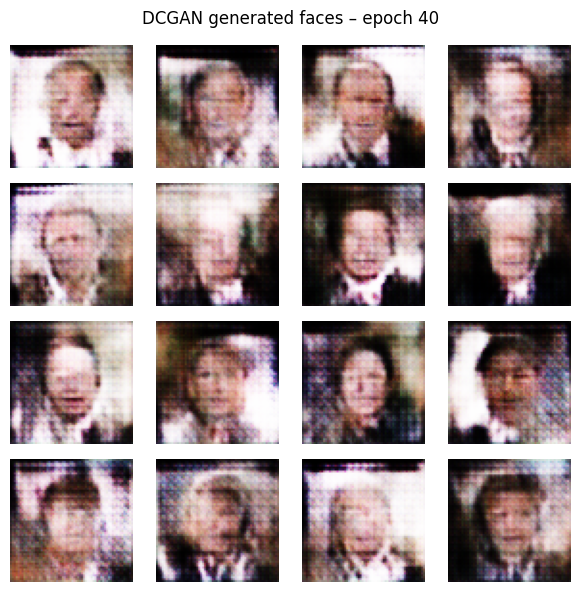

DCGAN training time: 138.8 seconds


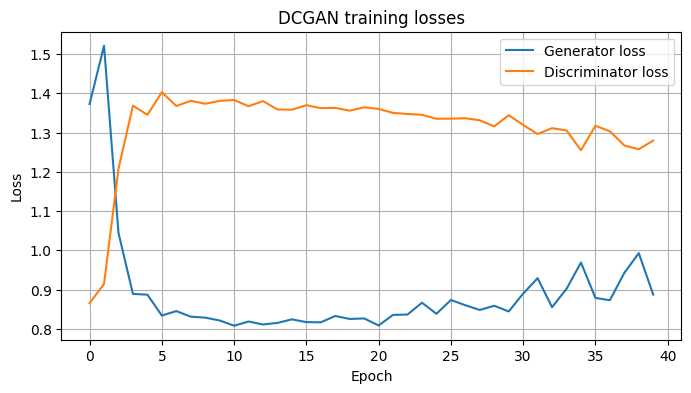

In [17]:
GAN_EPOCHS = 40
g_hist, d_hist = [], []
t0 = time.time()
for epoch in range(1, GAN_EPOCHS + 1):
    gl, dl = [], []
    for batch in gan_ds:
        g, d = dcgan_train_step(batch)
        gl.append(float(g)); dl.append(float(d))
    g_hist.append(np.mean(gl)); d_hist.append(np.mean(dl))
    print(f"Epoch {epoch:02d}/{GAN_EPOCHS} | G loss: {g_hist[-1]:.4f} | D loss: {d_hist[-1]:.4f}")
    if epoch in [1, 10, 20, 30, 40]:
        display_dcgan_samples(f"DCGAN generated faces – epoch {epoch}", f"figures/fig_gan_epoch{epoch}.png")
results["gan_time"] = time.time() - t0
results["gan_g"], results["gan_d"] = g_hist[-1], d_hist[-1]
print(f"DCGAN training time: {results['gan_time']:.1f} seconds")

plt.figure(figsize=(8, 4))
plt.plot(g_hist, label="Generator loss"); plt.plot(d_hist, label="Discriminator loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("DCGAN training losses"); plt.legend(); plt.grid(True)
plt.savefig("figures/fig_gan_loss.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Pretrained Diffusion Model – text-to-image
Uses pretrained `segmind/tiny-sd`. It is **not** trained on LFW, so this comparison is not like-for-like. The first run downloads weights; warnings about missing `.safetensors` files are harmless.

In [18]:
import time, torch
import numpy as np
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline
if 'results' not in globals(): results = {}

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


2.03s | A realistic close-up portrait photograph of a smiling middle-aged man, soft natural daylight, neutral background
2.04s | A realistic portrait photograph of a young woman with short dark hair, studio lighting, high detail
2.03s | A realistic portrait photograph of an elderly person with glasses, neutral background, high detail


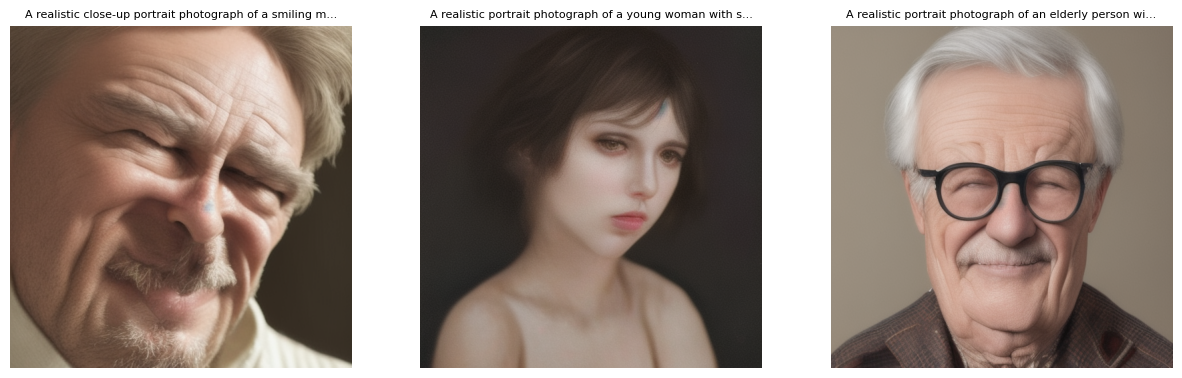

In [19]:
device = "cuda" if torch.cuda.is_available() else "cpu"
pipe = StableDiffusionPipeline.from_pretrained(
    "segmind/tiny-sd",
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    safety_checker=None).to(device)
pipe.set_progress_bar_config(disable=True)

PROMPTS = [
    "A realistic close-up portrait photograph of a smiling middle-aged man, soft natural daylight, neutral background",
    "A realistic portrait photograph of a young woman with short dark hair, studio lighting, high detail",
    "A realistic portrait photograph of an elderly person with glasses, neutral background, high detail",
]
with torch.inference_mode():
    pipe(PROMPTS[0], num_inference_steps=2)      # warm-up so timings are fair
    diff_images, diff_times = [], []
    for p in PROMPTS:
        t0 = time.time()
        diff_images.append(pipe(p, num_inference_steps=20, guidance_scale=7.0).images[0])
        diff_times.append(time.time() - t0)
        print(f"{diff_times[-1]:.2f}s | {p}")
results["diff_time"] = float(np.mean(diff_times))

fig, axes = plt.subplots(1, len(diff_images), figsize=(5*len(diff_images), 5.4))
for ax, im, p in zip(axes, diff_images, PROMPTS):
    ax.imshow(im); ax.axis("off"); ax.set_title(p[:55] + "...", fontsize=8)
plt.savefig("figures/fig_diffusion.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. Practical observations and timing

========== RESULTS SUMMARY (copy into the report) ==========
Model         Time (s)        MSE  PSNR (dB)     SSIM
AE                37.3    0.01030      20.24   0.5988
VAE               34.9    0.02337      16.60   0.4194
DCGAN            138.8   final G loss 0.8875, D loss 1.2795
Diffusion         2.03   inference, per 512x512 image


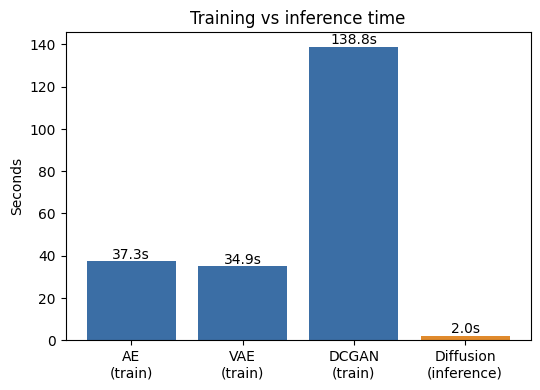

In [20]:
print("========== RESULTS SUMMARY (copy into the report) ==========")
print(f"{'Model':<12}{'Time (s)':>10}{'MSE':>11}{'PSNR (dB)':>11}{'SSIM':>9}")
for n, lab in [("ae", "AE"), ("vae", "VAE")]:
    print(f"{lab:<12}{results[n+'_time']:>10.1f}{results[n+'_mse']:>11.5f}{results[n+'_psnr']:>11.2f}{results[n+'_ssim']:>9.4f}")
print(f"{'DCGAN':<12}{results['gan_time']:>10.1f}   final G loss {results['gan_g']:.4f}, D loss {results['gan_d']:.4f}")
print(f"{'Diffusion':<12}{results['diff_time']:>10.2f}   inference, per 512x512 image")
print("=============================================================")

labels = ["AE\n(train)", "VAE\n(train)", "DCGAN\n(train)", "Diffusion\n(inference)"]
vals = [results["ae_time"], results["vae_time"], results["gan_time"], results["diff_time"]]
plt.figure(figsize=(6, 4))
bars = plt.bar(labels, vals, color=["#3b6ea5"]*3 + ["#e08a2c"])
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width()/2, v, f"{v:.1f}s", ha="center", va="bottom")
plt.ylabel("Seconds"); plt.title("Training vs inference time")
plt.savefig("figures/fig_time.png", dpi=150, bbox_inches="tight"); plt.show()

!zip -qr figures.zip figures      # download figures.zip from the Files panel for your report

### Observation prompts (write these in your own words from what you see)
- **AE:** Are face shape and colours kept? Is fine detail blurred?
- **VAE:** Is it smoother than the AE? Do sampled faces look face-like?
- **DCGAN:** Do samples look like faces? Are they varied or repeated? Did the losses stay near chance level?
- **Diffusion:** Does the image match the prompt? Any distortions (hands, eyes, teeth)?
- **Efficiency:** Compare training times with the per-image diffusion time separately.

## 9. Final comparison table

| Model | Main task | Key output to inspect |
|---|---|---|
| Autoencoder (AE) | Reconstruct an input image | Similarity to original; blur and lost details |
| Variational Autoencoder (VAE) | Reconstruct and learn a probabilistic latent space | Smoothness, similarity, sampled faces |
| DCGAN | Generate new images from random noise | Realism, diversity, repeated patterns |
| Pretrained Diffusion | Generate an image from a text prompt | Prompt relevance, realism, details, runtime |